# Where should a digital payments app investigate a pilot?

A payments app has resources to investigate one potential market. I want to identify a country where many adults have the basic ability to make digital payments, but relatively few report making them at merchants.

I will screen countries using World Bank Global Findex data, compare promising markets more closely, and recommend what the app should investigate before deciding whether to run a pilot.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

columns = [
    "countrynewwb", "codewb", "year", "pop_adult",
    "regionwb24_hi", "incomegroupwb24", "group", "group2",
    "internet", "account_t_d", "merchant_pay"
]

df = pd.read_csv(
    "data/GlobalFindexDatabase2025.csv",
    usecols=columns,
    na_values=["NA"],
    low_memory=False
)

display(df.head())

,countrynewwb,codewb,year,pop_adult,regionwb24_hi,incomegroupwb24,group,group2,account_t_d,merchant_pay,internet
0,Afghanistan,AFG,2011,14575546.0,South Asia (excluding high income),Low income,all,all,0.090050,NaN,NaN
1,Albania,ALB,2011,2281010.0,Europe & Central Asia (excluding high income),Upper middle income,all,all,0.282681,NaN,NaN
2,Algeria,DZA,2011,26251587.0,Middle East & North Africa (excluding high inc...,Lower middle income,all,all,0.332861,NaN,NaN
3,Angola,AGO,2011,12779501.0,Sub-Saharan Africa (excluding high income),Lower middle income,all,all,0.392035,NaN,NaN
4,Argentina,ARG,2011,30685516.0,Latin America & Caribbean (excluding high income),Upper middle income,all,all,0.331302,NaN,NaN


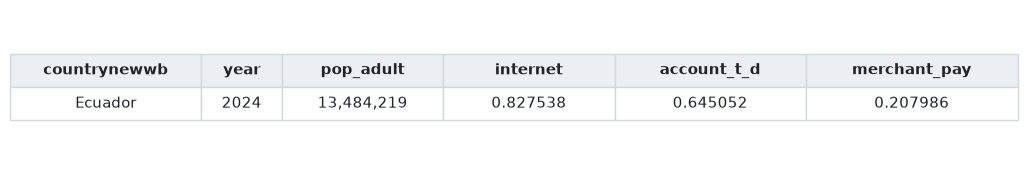

In [2]:
sample = df[
    (df["countrynewwb"] == "Ecuador")
    & (df["year"] == 2024)
    & (df["group"] == "all")
    & (df["group2"] == "all")
][
    ["countrynewwb", "year", "pop_adult",
     "internet", "account_t_d", "merchant_pay"]
].copy()

sample["pop_adult"] = sample["pop_adult"].map(lambda x: f"{x:,.0f}")

for column in ["internet", "account_t_d", "merchant_pay"]:
    sample[column] = sample[column].map(lambda x: f"{x:.6f}")

fig, ax = plt.subplots(figsize=(13, 2), facecolor="white")
ax.axis("off")

table = ax.table(
    cellText=sample.values,
    colLabels=sample.columns,
    cellLoc="center",
    loc="center",
    colWidths=[0.19, 0.08, 0.16, 0.17, 0.19, 0.21],
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2)

for (row, column), cell in table.get_celld().items():
    cell.set_edgecolor("#D2D8DE")
    cell.set_facecolor("#EBEFF3" if row == 0 else "white")
    cell.get_text().set_color("#20242B")
    if row == 0:
        cell.get_text().set_weight("bold")

plt.savefig(
    "dataset_sample_row_white.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

### Check the years, population groups, and duplicate rows

In [3]:
print("Rows and loaded columns:", df.shape)

print("\nRows by year:")
print(df["year"].value_counts().sort_index())

print("\nPopulation groups:")
display(
    df[["group", "group2"]]
    .drop_duplicates()
    .sort_values(["group", "group2"])
)

duplicate_rows = df.duplicated(
    subset=["codewb", "year", "group", "group2"]
).sum()

print("\nDuplicate country-year-group rows:", duplicate_rows)

Rows and loaded columns: (8577, 11)

Rows by year:
year
2011    1516
2014    1686
2017    1734
2021    1483
2022     176
2024    1982
Name: count, dtype: int64

Population groups:


,group,group2
3466,age_cat,age 25+
3467,age_cat,ages 15-24
0,all,all
6506,education,prim edu or less
6505,education,secondary edu or more
712,gender,men
713,gender,women
2103,income,poorest 40%
2102,income,richest 60%
5136,laborforce,in laborforce



Duplicate country-year-group rows: 0


### Select individual countries in 2024

For the main comparison, I need one overall estimate per country. I'll keep 2024 rows where population-group fields = all


In [4]:
country_2024 = df[
    (df["year"] == 2024)
    & (df["group"] == "all")
    & (df["group2"] == "all")
    & (df["pop_adult"].notna())
].copy()

print("Individual countries in 2024:", len(country_2024))

print("\nCountries with each measure available:")
print(
    country_2024[
        ["internet", "account_t_d", "merchant_pay"]
    ].notna().sum()
)

print("\nCountries by income group:")
print(country_2024["incomegroupwb24"].value_counts())

Individual countries in 2024: 141

Countries with each measure available:
internet        141
account_t_d     141
merchant_pay     98
dtype: int64

Countries by income group:
incomegroupwb24
High income            48
Lower middle income    40
Upper middle income    37
Low income             16
Name: count, dtype: int64


### Define comparable mkts

In [5]:
income_groups = [
    "Low income",
    "Lower middle income",
    "Upper middle income"
]

markets = country_2024[
    country_2024["incomegroupwb24"].isin(income_groups)
].dropna(
    subset=["internet", "account_t_d", "merchant_pay"]
).copy()

print("Countries with all three measures:", len(markets))

display(
    markets[
        ["countrynewwb", "regionwb24_hi", "incomegroupwb24",
         "internet", "account_t_d", "merchant_pay"]
    ].head()
)

Countries with all three measures: 92


,countrynewwb,regionwb24_hi,incomegroupwb24,internet,account_t_d,merchant_pay
571,Albania,Europe & Central Asia (excluding high income),Upper middle income,0.828402,0.460693,0.110836
572,Algeria,Middle East & North Africa (excluding high inc...,Lower middle income,0.829104,0.352901,0.070034
573,Argentina,Latin America & Caribbean (excluding high income),Upper middle income,0.881293,0.817442,0.601935
574,Armenia,Europe & Central Asia (excluding high income),Upper middle income,0.875233,0.713735,0.338039
577,Azerbaijan,Europe & Central Asia (excluding high income),Upper middle income,0.863524,0.563047,0.342396


In [6]:
ecuador = markets.loc[markets["codewb"].eq("ECU")].iloc[0]

regional_peers = markets.loc[
    markets["codewb"].ne("ECU")
    & markets["regionwb24_hi"].eq(ecuador["regionwb24_hi"])
    & markets["pop_adult"].ge(2_000_000)
].copy()

regional_peers["access_distance_pp"] = (
    ((regional_peers["internet"] - ecuador["internet"]) * 100) ** 2
    + ((regional_peers["account_t_d"] - ecuador["account_t_d"]) * 100) ** 2
) ** 0.5

display(
    regional_peers.nsmallest(5, "access_distance_pp")[
        ["countrynewwb", "internet", "account_t_d",
         "merchant_pay", "access_distance_pp"]
    ]
)

,countrynewwb,internet,account_t_d,merchant_pay,access_distance_pp
673,Paraguay,0.838436,0.609168,0.259604,3.750273
605,Dominican Republic,0.893376,0.647780,0.276284,6.589422
674,Peru,0.781495,0.593099,0.327198,6.941999
595,Colombia,0.806874,0.570595,0.261229,7.727145
599,Costa Rica,0.873855,0.713527,0.472497,8.266820


### Scope of the comparison

I use 2024 results by country for adults aged 15 and older. I compare low and middle income markets with available figures for internet use, account ownership, and digital merchant payments.

In [7]:
print("Individual countries in 2024:", len(country_2024))
print(
    "Countries with a merchant-payment figure:",
    country_2024["merchant_pay"].notna().sum()
)
print("Countries in the main comparison:", len(markets))

Individual countries in 2024: 141
Countries with a merchant-payment figure: 98
Countries in the main comparison: 92


### market analysis

,countries,median_payment_pct
regionwb24_hi,,
Middle East & North Africa (excluding high income),10,8.9
South Asia (excluding high income),5,9.3
Sub-Saharan Africa (excluding high income),35,12.0
Latin America & Caribbean (excluding high income),16,26.0
Europe & Central Asia (excluding high income),17,38.1
East Asia & Pacific (excluding high income),9,51.1


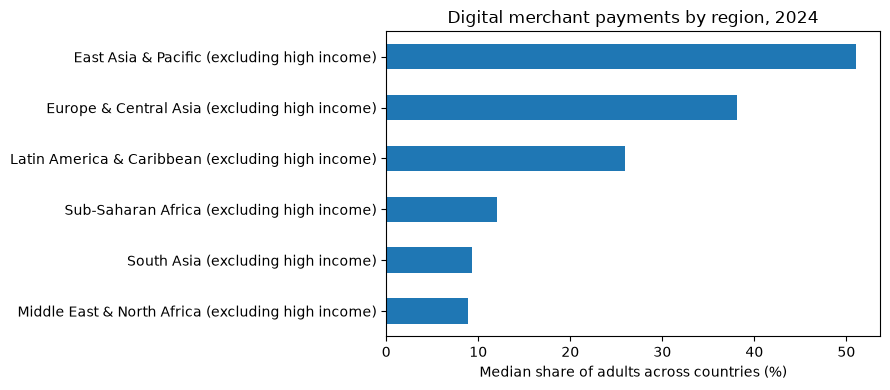

In [8]:
region_summary = markets.groupby("regionwb24_hi").agg(
    countries=("codewb", "count"),
    median_payment=("merchant_pay", "median")
)

region_summary["median_payment_pct"] = (
    region_summary["median_payment"] * 100
).round(1)

region_summary = region_summary.sort_values("median_payment_pct")

display(region_summary[["countries", "median_payment_pct"]])

region_summary["median_payment_pct"].plot(
    kind="barh",
    figsize=(9, 4)
)

plt.title("Digital merchant payments by region, 2024")
plt.xlabel("Median share of adults across countries (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

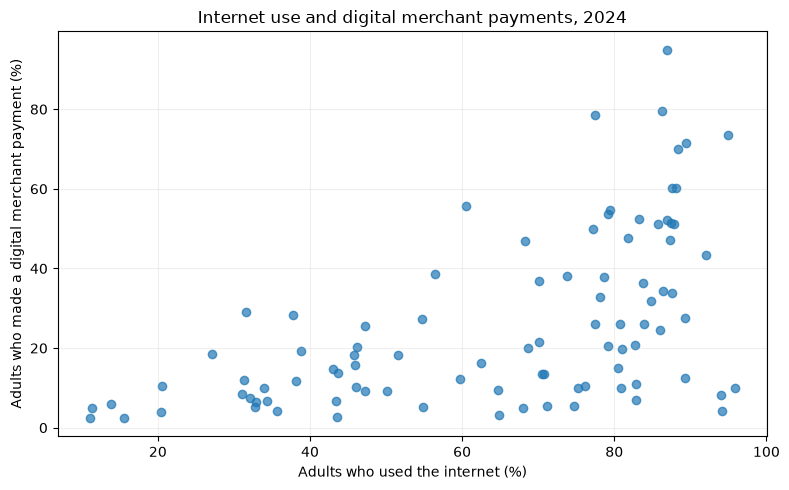

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    markets["internet"] * 100,
    markets["merchant_pay"] * 100,
    alpha=0.7
)

plt.title("Internet use and digital merchant payments, 2024")
plt.xlabel("Adults who used the internet (%)")
plt.ylabel("Adults who made a digital merchant payment (%)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## K-means clustering to group countries with similar access

K-means groups countries using internet use and account ownership. I standardize these 2 measures first so that each contributes to the grouping. I use 3 groups as an exploratory choice and then check whether changing that choice affects the shortlist.


In [10]:
features = markets[["internet", "account_t_d"]]

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

markets["peer_group"] = model.fit_predict(scaled_features) + 1

peer_summary = (
    markets
    .groupby("peer_group")[
        ["internet", "account_t_d", "merchant_pay"]
    ]
    .median() * 100
)

peer_summary.insert(
    0,
    "countries",
    markets.groupby("peer_group")["codewb"].count()
)

print("Median percentages in each group:")
display(peer_summary.round(1))

Median percentages in each group:


,countries,internet,account_t_d,merchant_pay
peer_group,,,,
1,29,77.5,43.4,12.5
2,34,85.3,81.6,48.7
3,29,34.3,52.2,9.3


### Countries analysis

In [11]:
markets["peer_payment_median"] = (
    markets.groupby("peer_group")["merchant_pay"]
    .transform("median")
)

markets["gap_pp"] = (
    markets["merchant_pay"]
    - markets["peer_payment_median"]
) * 100

candidates = markets[
    (markets["internet"] >= 0.65)
    & (markets["account_t_d"] >= 0.60)
    & (markets["pop_adult"] >= 2_000_000)
].copy()

shortlist = candidates.nsmallest(5, "gap_pp").copy()

shortlist_table = pd.DataFrame({
    "Country": shortlist["countrynewwb"],
    "Adults (millions)": (shortlist["pop_adult"] / 1_000_000).round(1),
    "Internet (%)": (shortlist["internet"] * 100).round(1),
    "Accounts (%)": (shortlist["account_t_d"] * 100).round(1),
    "Merchant payments (%)": (
        shortlist["merchant_pay"] * 100
    ).round(1),
    "Versus peer median (pp)": shortlist["gap_pp"].round(1)
})

print("Countries passing the initial screen:", len(candidates))
display(shortlist_table)

Countries passing the initial screen: 24


,Country,Adults (millions),Internet (%),Accounts (%),Merchant payments (%),Versus peer median (pp)
606,Ecuador,13.5,82.8,64.5,20.8,-27.9
605,Dominican Republic,8.3,89.3,64.8,27.6,-21.1
584,Bosnia and Herzegovina,2.8,84.8,77.5,31.8,-17.0
574,Armenia,2.4,87.5,71.4,33.8,-14.9
681,Senegal,11.1,70.1,76.5,37.0,-11.8


### Compare Ecuador with markets nearby

Ecuador median includes countries with quite different levels of account ownership. I compare Ecuador with Paraguay and the Dominican Republic which are in the same broad region with similar internet and account access.

,Adults (millions),Internet (%),Accounts (%),Merchant payments (%)
Country,,,,
Ecuador,13.5,82.8,64.5,20.8
Paraguay,4.9,83.8,60.9,26.0
Dominican Republic,8.3,89.3,64.8,27.6


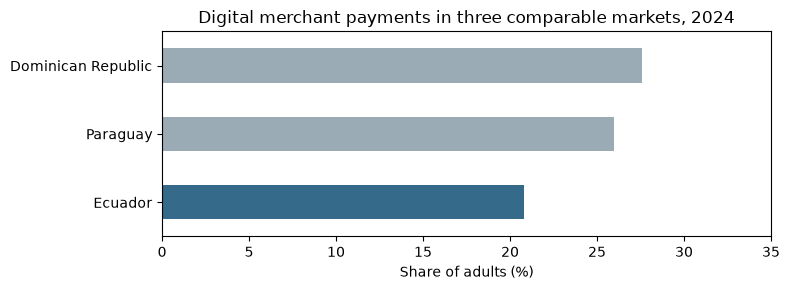

In [12]:
peer_codes = ["ECU", "PRY", "DOM"]

peer_countries = country_2024[
    country_2024["codewb"].isin(peer_codes)
].copy()

peer_table = pd.DataFrame({
    "Country": peer_countries["countrynewwb"],
    "Adults (millions)": (
        peer_countries["pop_adult"] / 1_000_000
    ).round(1),
    "Internet (%)": (
        peer_countries["internet"] * 100
    ).round(1),
    "Accounts (%)": (
        peer_countries["account_t_d"] * 100
    ).round(1),
    "Merchant payments (%)": (
        peer_countries["merchant_pay"] * 100
    ).round(1)
}).set_index("Country").loc[
    ["Ecuador", "Paraguay", "Dominican Republic"]
]

display(peer_table)

ax = peer_table["Merchant payments (%)"].plot(
    kind="barh",
    figsize=(8, 3),
    color=["#356A8A", "#9AABB5", "#9AABB5"]
)
ax.set_title("Digital merchant payments in three comparable markets, 2024")
ax.set_xlabel("Share of adults (%)")
ax.set_ylabel("")
ax.set_xlim(0, 35)

plt.tight_layout()
plt.show()

### Did the difference narrow over time?

I compare the same reported merchant-payment measure in 2021 and 2024 for the 3 markets. 

In [13]:
previous = df[
    (df["year"] == 2021)
    & (df["group"] == "all")
    & (df["group2"] == "all")
][["codewb", "merchant_pay"]].rename(
    columns={"merchant_pay": "merchant_pay_2021"}
)

peer_history = peer_countries.merge(
    previous,
    on="codewb",
    how="left"
)

trend_table = pd.DataFrame({
    "Country": peer_history["countrynewwb"],
    "2021 (%)": (
        peer_history["merchant_pay_2021"] * 100
    ).round(1),
    "2024 (%)": (
        peer_history["merchant_pay"] * 100
    ).round(1),
    "Change (pp)": (
        (peer_history["merchant_pay"]
         - peer_history["merchant_pay_2021"]) * 100
    ).round(1)
}).set_index("Country").loc[
    ["Ecuador", "Paraguay", "Dominican Republic"]
]

display(trend_table)

,2021 (%),2024 (%),Change (pp)
Country,,,
Ecuador,15.9,20.8,4.9
Paraguay,10.0,26.0,16.0
Dominican Republic,13.2,27.6,14.4


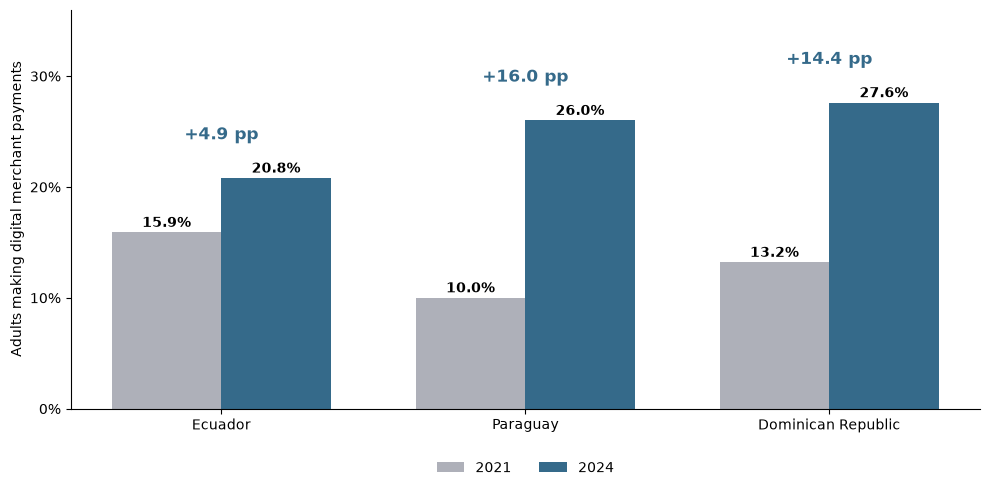

In [14]:
countries = ["Ecuador", "Paraguay", "Dominican Republic"]
chart_data = trend_table.loc[countries]

values_2021 = chart_data["2021 (%)"].tolist()
values_2024 = chart_data["2024 (%)"].tolist()
changes = chart_data["Change (pp)"].tolist()

x = [0, 1, 2]
bar_width = 0.36
x_2021 = [position - bar_width / 2 for position in x]
x_2024 = [position + bar_width / 2 for position in x]

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(x_2021, values_2021, width=bar_width,
       color="#AEB0B9", label="2021")
ax.bar(x_2024, values_2024, width=bar_width,
       color="#356A8A", label="2024")

for i in range(len(countries)):
    ax.text(x_2021[i], values_2021[i] + 0.5,
            f"{values_2021[i]:.1f}%",
            ha="center", fontweight="bold")

    ax.text(x_2024[i], values_2024[i] + 0.5,
            f"{values_2024[i]:.1f}%",
            ha="center", fontweight="bold")

    ax.text(x[i], max(values_2021[i], values_2024[i]) + 3.5,
            f"+{changes[i]:.1f} pp",
            ha="center", color="#356A8A",
            fontweight="bold", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(countries)
ax.set_ylim(0, 36)
ax.set_yticks([0, 10, 20, 30])
ax.set_yticklabels(["0%", "10%", "20%", "30%"])
ax.set_ylabel("Adults making digital merchant payments")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10),
          ncol=2, frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Check differences in countries

For shortlisted countries, I compare reported merchant payment use between genders and between the poorest 40% and richest 60% of households.


In [15]:
demographics = df[
    (df["year"] == 2024)
    & (df["codewb"].isin(shortlist["codewb"]))
    & (df["group"].isin(["gender", "income"]))
].copy()

demographics["payment_pct"] = (
    demographics["merchant_pay"] * 100
)

gender = demographics[
    demographics["group"] == "gender"
].pivot(
    index="countrynewwb",
    columns="group2",
    values="payment_pct"
)

gender["Men minus women (pp)"] = (
    gender["men"] - gender["women"]
)

print("Merchant payment use by gender (% of each group):")
display(gender.round(1))

income = demographics[
    demographics["group"] == "income"
].pivot(
    index="countrynewwb",
    columns="group2",
    values="payment_pct"
)

income["Richest minus poorest (pp)"] = (
    income["richest 60%"] - income["poorest 40%"]
)

print("Merchant payment use by household income group (% of each group):")
display(income.round(1))

Merchant payment use by gender (% of each group):


group2,men,women,Men minus women (pp)
countrynewwb,,,
Armenia,34.5,33.2,1.3
Bosnia and Herzegovina,30.0,33.5,-3.5
Dominican Republic,33.1,22.3,10.8
Ecuador,25.8,16.2,9.6
Senegal,40.9,33.4,7.6


Merchant payment use by household income group (% of each group):


group2,poorest 40%,richest 60%,Richest minus poorest (pp)
countrynewwb,,,
Armenia,26.4,38.7,12.3
Bosnia and Herzegovina,21.5,38.6,17.0
Dominican Republic,11.2,38.5,27.3
Ecuador,9.2,28.6,19.4
Senegal,31.0,40.9,9.9


### What should i investigate in Ecuador?

The overall merchant-payment measure includes purchases in stores or online. I look specifically at in-store card or phone payments and reported reasons for paying cash in stores.

The reasons are survey responses, not proof that a particular barrier caused Ecuador's lower payment use.

In [16]:
reason_cols = [
    "fin25e2", "fin25e4a", "fin25e4b",
    "fin25e4c", "fin25e4d"
]

detail = pd.read_csv(
    "data/GlobalFindexDatabase2025.csv",
    usecols=["codewb", "year", "group", "group2"] + reason_cols,
    na_values=["NA"],
    low_memory=False
)

detail = detail[
    (detail["year"] == 2024)
    & (detail["group"] == "all")
    & (detail["group2"] == "all")
    & (detail["codewb"].isin(peer_codes))
].copy()

detail["Country"] = detail["codewb"].map({
    "ECU": "Ecuador",
    "PRY": "Paraguay",
    "DOM": "Dominican Republic"
})

cash_table = (
    detail.set_index("Country")[reason_cols] * 100
).round(1)

cash_table.columns = [
    "In-store card/phone payment (%)",
    "Merchant only takes cash (%)",
    "Card/phone costs more (%)",
    "Distrusts card/phone (%)",
    "Used to paying cash (%)"
]

display(
    cash_table.loc[
        ["Ecuador", "Paraguay", "Dominican Republic"]
    ]
)

,In-store card/phone payment (%),Merchant only takes cash (%),Card/phone costs more (%),Distrusts card/phone (%),Used to paying cash (%)
Country,,,,,
Ecuador,18.7,4.2,2.5,2.4,31.4
Paraguay,25.6,0.5,0.5,0.8,36.1
Dominican Republic,26.0,0.8,0.7,1.9,27.3


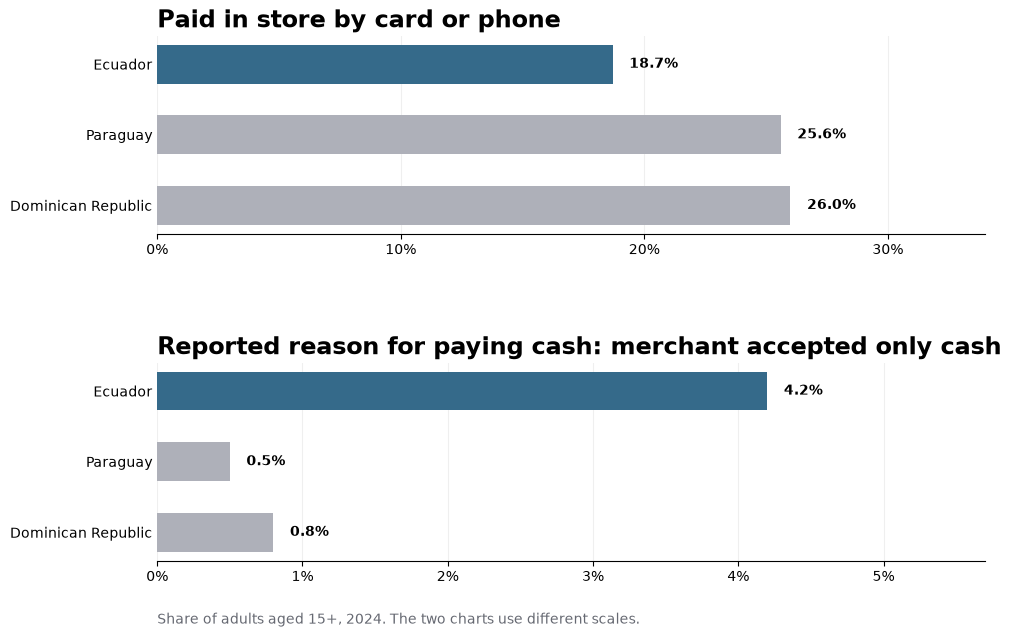

In [17]:
countries = ["Ecuador", "Paraguay", "Dominican Republic"]
colors = ["#356A8A", "#AEB0B9", "#AEB0B9"]

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
fig.subplots_adjust(left=0.26, right=0.95, top=0.88,
                    bottom=0.13, hspace=0.65)

chart_details = [
    (
        "Paid in store by card or phone",
        "In-store card/phone payment (%)",
        34,
        [0, 10, 20, 30]
    ),
    (
        "Reported reason for paying cash: merchant accepted only cash",
        "Merchant only takes cash (%)",
        5.7,
        [0, 1, 2, 3, 4, 5]
    )
]

for ax, (title, column, limit, ticks) in zip(axes, chart_details):
    values = cash_table.loc[countries, column]
    bars = ax.barh(countries, values, color=colors, height=0.55)

    ax.invert_yaxis()
    ax.set_title(title, loc="left", fontweight="bold", fontsize=17)
    ax.set_xlim(0, limit)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{tick}%" for tick in ticks])
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values):
        ax.text(value + limit * 0.02,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.1f}%",
                va="center", fontweight="bold")

    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="y", length=0)

fig.text(0.26, 0.04,
         "Share of adults aged 15+, 2024. The two charts use different scales.",
         color="#666972", fontsize=10)

fig.savefig("in_store_and_cash_reason.png",
            dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

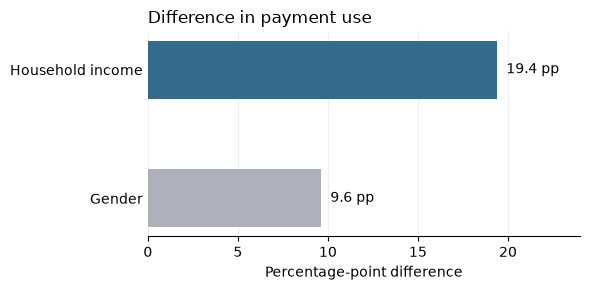

In [18]:
labels = ["Household income", "Gender"]
gaps = [
    income.loc["Ecuador", "Richest minus poorest (pp)"],
    gender.loc["Ecuador", "Men minus women (pp)"],
]

fig, ax = plt.subplots(figsize=(6, 3), facecolor="white")
ax.barh(labels, gaps, color=["#356A8A", "#AEB0B9"], height=0.45)
ax.invert_yaxis()
ax.set_xlim(0, 24)
ax.set_xlabel("Percentage-point difference")
ax.set_title("Difference in payment use", loc="left")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)

for position, value in enumerate(gaps):
    ax.text(value + 0.5, position, f"{value:.1f} pp", va="center")

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.savefig("ecuador_group_differences.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

### Check if shortlist is fragile
The shortlist depends partly on my screening rules and on the number of K-means groups. I will see whether the leading countries change when I make the access requirements stricter or use 2/4 peer groups.

If a country appears only under one narrow set of choices, I should be cautious about recommending it.

In [19]:
# Change account ownership cutoff from 60% to 55%
candidates_55 = markets[
    (markets["internet"] >= 0.65)
    & (markets["account_t_d"] >= 0.55)
    & (markets["pop_adult"] >= 2_000_000)
].copy()

print("Countries with the original 60% cutoff:", len(candidates))
print("Countries with a 55% cutoff:", len(candidates_55))

bolivia_ecuador = candidates_55[
    candidates_55["codewb"].isin(["BOL", "ECU"])
].copy()

bolivia_ecuador["Internet (%)"] = (
    bolivia_ecuador["internet"] * 100
).round(1)

bolivia_ecuador["Accounts (%)"] = (
    bolivia_ecuador["account_t_d"] * 100
).round(1)

bolivia_ecuador["Merchant payments (%)"] = (
    bolivia_ecuador["merchant_pay"] * 100
).round(1)

display(
    bolivia_ecuador[
        ["countrynewwb", "Internet (%)",
         "Accounts (%)", "Merchant payments (%)"]
    ].sort_values("Merchant payments (%)")
)

Countries with the original 60% cutoff: 24
Countries with a 55% cutoff: 30


,countrynewwb,Internet (%),Accounts (%),Merchant payments (%)
583,Bolivia,79.1,56.8,20.5
606,Ecuador,82.8,64.5,20.8


In [20]:
for account_cutoff in [0.60, 0.55]:
    eligible = markets[
        (markets["internet"] >= 0.65)
        & (markets["account_t_d"] >= account_cutoff)
        & (markets["pop_adult"] >= 2_000_000)
    ]

    print(f"{account_cutoff:.0%} account cutoff: {len(eligible)} countries")

60% account cutoff: 24 countries
55% account cutoff: 30 countries


Lowering the cutoff from 60% to 55% increases the eligible countries from 24 to 30 and brings Bolivia into consideration. Bolivia's reported merchant-payment use (20.5%) is close to Ecuador's (20.8%), even if Bolivia has lower account ownership (56.8% vs 64.5%).

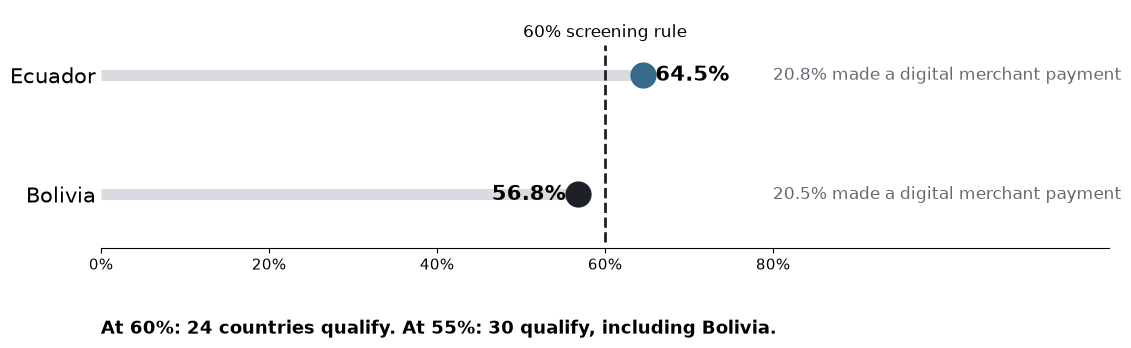

In [21]:
cutoff_rows = (
    country_2024[
        country_2024["codewb"].isin(["ECU", "BOL"])
    ]
    .set_index("codewb")
)

fig, ax = plt.subplots(figsize=(12, 4.5), facecolor="white")
fig.subplots_adjust(left=0.13, right=0.97, top=0.78, bottom=0.25)

countries = [
    ("ECU", "Ecuador", 1, "#356A8A"),
    ("BOL", "Bolivia", 0, "#1E2028"),
]

for code, name, y, color in countries:
    account_pct = cutoff_rows.loc[code, "account_t_d"] * 100
    payment_pct = cutoff_rows.loc[code, "merchant_pay"] * 100

    ax.hlines(y, 0, account_pct, color="#DADBE1", linewidth=8)
    ax.scatter(account_pct, y, color=color, s=320, zorder=3)

    if code == "ECU":
        ax.text(account_pct + 1.5, y, f"{account_pct:.1f}%",
                va="center", fontweight="bold", fontsize=15)
    else:
        ax.text(account_pct - 1.5, y, f"{account_pct:.1f}%",
                ha="right", va="center",
                fontweight="bold", fontsize=15)

    ax.text(80, y,
            f"{payment_pct:.1f}% made a digital merchant payment",
            va="center", color="#666972", fontsize=12)

ax.vlines(60, -0.4, 1.25, color="#1E2028",
          linestyle="--", linewidth=2)
ax.text(60, 1.32, "60% screening rule",
        ha="center", fontsize=12)

ax.set_xlim(0, 120)
ax.set_ylim(-0.45, 1.55)
ax.set_yticks([1, 0], ["Ecuador", "Bolivia"])
ax.set_xticks([0, 20, 40, 60, 80],
              ["0%", "20%", "40%", "60%", "80%"])
ax.tick_params(axis="y", length=0, labelsize=15)
ax.tick_params(axis="x", labelsize=11)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

fig.text(
    0.13, 0.06,
    f"At 60%: {len(candidates)} countries qualify. "
    f"At 55%: {len(candidates_55)} qualify, including Bolivia.",
    fontsize=13, fontweight="bold"
)
plt.show()

In [22]:
stricter = markets[
    (markets["internet"] >= 0.70)
    & (markets["account_t_d"] >= 0.65)
    & (markets["pop_adult"] >= 2_000_000)
]

print("Countries passing the stricter screen:", len(stricter))
print("Five largest gaps under the stricter screen:")

display(
    stricter.nsmallest(5, "gap_pp")[
        ["countrynewwb", "internet", "account_t_d",
         "merchant_pay", "gap_pp"]
    ].round(3)
)

Countries passing the stricter screen: 20
Five largest gaps under the stricter screen:


,countrynewwb,internet,account_t_d,merchant_pay,gap_pp
584,Bosnia and Herzegovina,0.848,0.775,0.318,-16.956
574,Armenia,0.875,0.714,0.338,-14.935
681,Senegal,0.701,0.765,0.370,-11.766
640,Kyrgyz Republic,0.920,0.723,0.434,-5.339
599,Costa Rica,0.874,0.714,0.472,-1.489


In [23]:
for k in [2, 3, 4]:
    check = markets.copy()

    check["group_k"] = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    ).fit_predict(scaled_features)

    check["gap_k"] = (
        check["merchant_pay"]
        - check.groupby("group_k")["merchant_pay"].transform("median")
    ) * 100

    check = check[
        (check["internet"] >= 0.65)
        & (check["account_t_d"] >= 0.60)
        & (check["pop_adult"] >= 2_000_000)
    ]

    top_three = check.nsmallest(
        3, "gap_k"
    )["countrynewwb"].tolist()

    print(f"{k} peer groups: {top_three}")

2 peer groups: ['Ecuador', 'Paraguay', 'Dominican Republic']
3 peer groups: ['Ecuador', 'Dominican Republic', 'Bosnia and Herzegovina']
4 peer groups: ['Ecuador', 'Dominican Republic', 'Bosnia and Herzegovina']


## Conclusions

Ecuador is a reasonable candidate for the first investigation, with Paraguay and the Dominican Republic as comparison markets. In 2024 reported digital merchant payments reached 20.8% of adults in Ecuador, compared with 26.0% and 27.6% in the comparison countries. Ecuador also had lower reported in-store card/phone payment use.

Ecuador's merchant-payment figure rose by 4.9 percentage points between 2021 and 2024, compared with 16.0 points in Paraguay and 14.4 points in the Dominican Republic. Some respondents reported that merchants accepted only cash as their main reason for paying cash in stores. This is a question for follow up research.

This is a shortlist for research, not evidence that Ecuador is the best place to launch. The country differences are survey estimates; the selected comparison countries are not identical. Ecuador also fails my stricter 65% account-ownership screen by a small margin (its figure is 64.5%). K-means results depend on the number of groups, and the broad cluster median is not a reliable estimate of Ecuador's potential.
Lowering the account-ownership cutoff to 55% also brings Bolivia into consideration. Its reported merchant-payment use is close to Ecuador’s, so the recommendation depends partly on where I set the initial screen.

**Next steps** 
Check current competition, payment fees, regulation, and merchant acceptance in the three markets. Interview customers and merchants to test why people use cash. If Ecuador remains attractive after those checks, design a limited pilot and measure first successful payment, repeat use, and customer acquisition cost before considering a broader launch.